In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

**SLpM** - Significant Strikes Landed per Minute

**Str. Acc.** - Significant Striking Accuracy

**SApM** - Significant Strikes Absorbed per Minute

**Str. Def.** - Significant Strike Defence (the % of opponents strikes that did not land)

**TD Avg.** - Average Takedowns Landed per 15 minutes

**TD Acc.** - Takedown Accuracy

**TD Def.** - Takedown Defense (the % of opponents TD attempts that did not land)

**Sub. Avg.** - Average Submissions Attempted per 15 minutes

In [3]:
fighter_df = pd.read_csv("fighter.csv")
fighter_df.describe()

,weight_lbs,reach_inches,slpm,str_acc,sapm,str_def,td_avg,td_acc,td_def,sub_avg
count,4493.000000,2589.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000
mean,169.777654,71.508691,2.479932,35.702685,3.218422,42.402750,1.246285,25.702467,39.929273,0.566710
std,39.462430,4.280318,1.986239,20.280797,2.961669,22.183612,1.939417,27.969000,34.390822,1.428137
min,105.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,145.000000,69.000000,0.850000,27.000000,1.620000,35.000000,0.000000,0.000000,0.000000,0.000000
50%,155.000000,72.000000,2.400000,41.000000,2.980000,50.000000,0.580000,22.000000,45.000000,0.000000
75%,185.000000,75.000000,3.680000,49.000000,4.300000,57.000000,1.910000,44.000000,66.000000,0.700000
max,770.000000,84.000000,17.650000,100.000000,52.500000,100.000000,32.140000,100.000000,100.000000,21.900000


Peleadores con estadísticas: 3827 de 4581


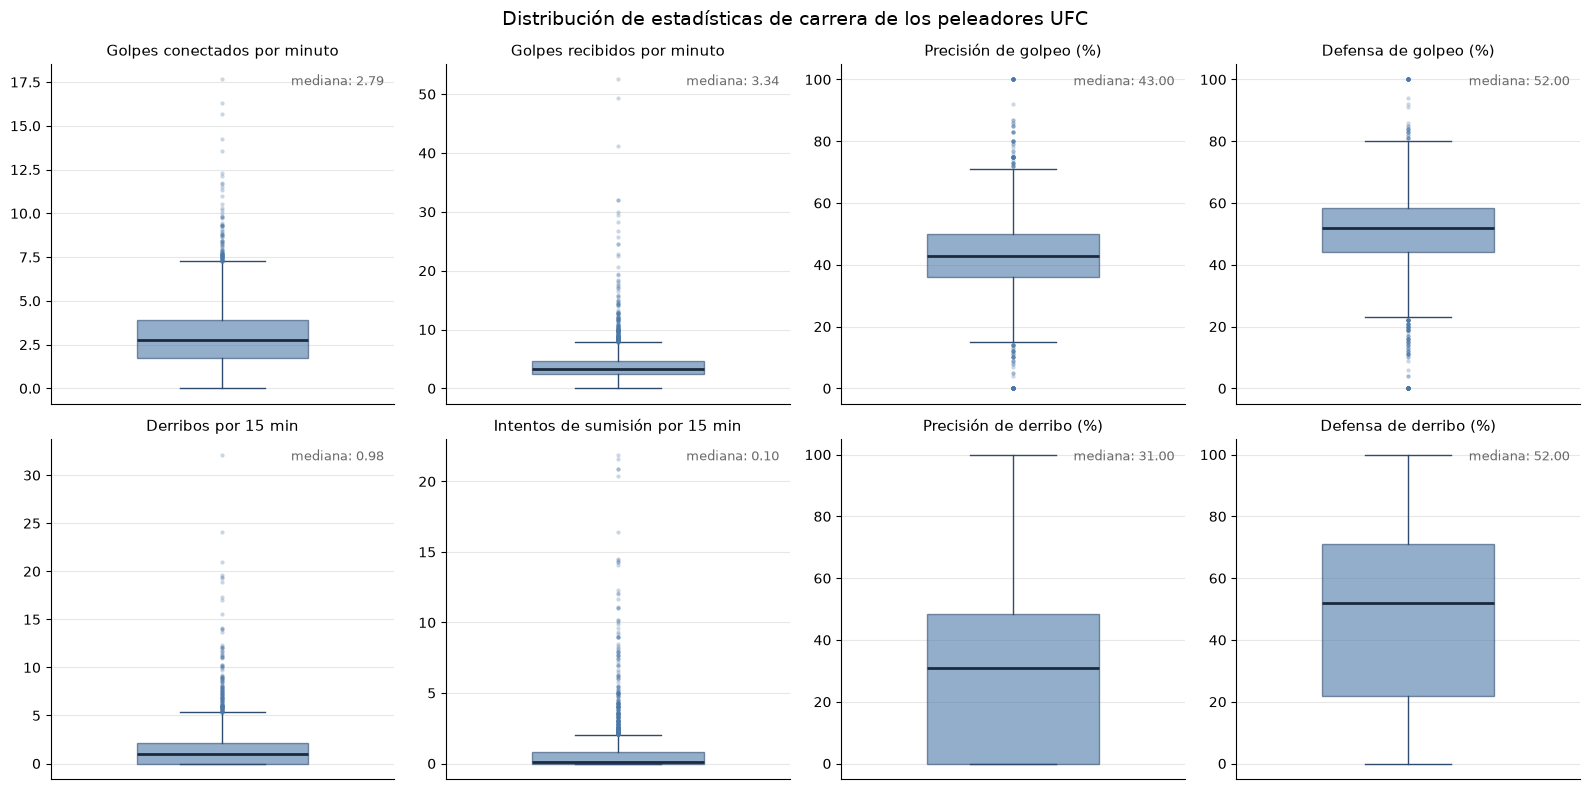

In [4]:
estadisticas = {
    "slpm": "Golpes conectados por minuto",
    "sapm": "Golpes recibidos por minuto",
    "str_acc": "Precisión de golpeo (%)",
    "str_def": "Defensa de golpeo (%)",
    "td_avg": "Derribos por 15 min",
    "sub_avg": "Intentos de sumisión por 15 min",
    "td_acc": "Precisión de derribo (%)",
    "td_def": "Defensa de derribo (%)",
}
cols = list(estadisticas)

# Peleadores sin estadísticas registradas tienen todo en 0: se excluyen
stats_df = fighter_df.loc[~(fighter_df[cols] == 0).all(axis=1), cols]
print(f"Peleadores con estadísticas: {len(stats_df)} de {len(fighter_df)}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (col, titulo) in zip(axes.flat, estadisticas.items()):
    datos = stats_df[col].dropna()
    ax.boxplot(
        datos,
        widths=0.5,
        patch_artist=True,
        boxprops=dict(facecolor="#4C78A8", alpha=0.6, edgecolor="#2F4B6E"),
        medianprops=dict(color="#1B2A3D", linewidth=2),
        whiskerprops=dict(color="#2F4B6E"),
        capprops=dict(color="#2F4B6E"),
        flierprops=dict(
            marker="o",
            markersize=3,
            markerfacecolor="#4C78A8",
            markeredgecolor="none",
            alpha=0.3,
        ),
    )
    ax.set_title(titulo, fontsize=11)
    ax.set_xticks([])
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(
        0.97,
        0.97,
        f"mediana: {datos.median():.2f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        color="dimgray",
    )

fig.suptitle(
    "Distribución de estadísticas de carrera de los peleadores UFC", fontsize=14
)
fig.tight_layout()
plt.show()

Peleadores en la regresión: 3659 (excluidos 168 sin peleas en fight.csv)


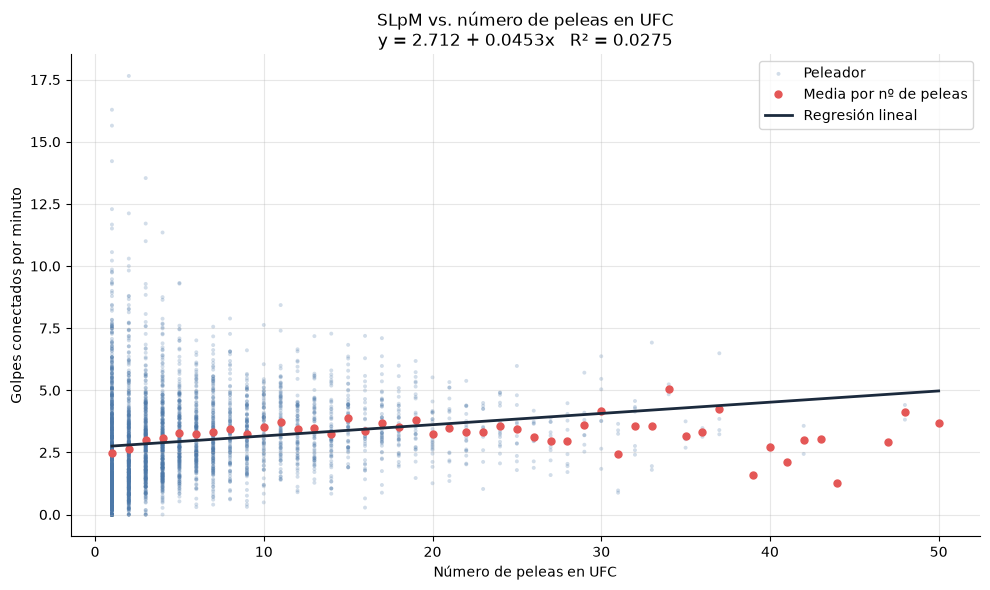

intercepto       2.7115
pendiente        0.0453
error_std        0.0045
t               10.1597
R2               0.0275
RMSE             1.7851
n             3659.0000
dtype: float64

In [5]:
# Regresión: SLpM ~ número de peleas en UFC
fight_df = pd.read_csv("fight.csv")

# Cada pelea cuenta para ambos peleadores (esquina roja y azul)
n_peleas = pd.concat([fight_df["r_id"], fight_df["b_id"]]).value_counts()

peleas_df = fighter_df.loc[
    stats_df.index, ["fighter_id", "fighter_name", "slpm"]
].copy()
peleas_df["n_peleas"] = peleas_df["fighter_id"].map(n_peleas).fillna(0).astype(int)

# Se excluyen peleadores con estadísticas pero sin peleas registradas en fight.csv
sin_peleas = (peleas_df["n_peleas"] == 0).sum()
peleas_df = peleas_df[peleas_df["n_peleas"] > 0]
print(
    f"Peleadores en la regresión: {len(peleas_df)} (excluidos {sin_peleas} sin peleas en fight.csv)"
)

X = peleas_df[["n_peleas"]].to_numpy(float)
y = peleas_df["slpm"].to_numpy(float)
modelo = LinearRegression().fit(X, y)
y_pred = modelo.predict(X)

n = len(y)
x = X[:, 0]
residuos = y - y_pred
se = np.sqrt(residuos @ residuos / (n - 2) / ((x - x.mean()) ** 2).sum())
pendiente, intercepto = modelo.coef_[0], modelo.intercept_
r2 = r2_score(y, y_pred)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, s=8, alpha=0.25, color="#4C78A8", edgecolors="none", label="Peleador")
# Media de SLpM por número de peleas, como referencia frente a la recta
medias = peleas_df.groupby("n_peleas")["slpm"].mean()
ax.plot(
    medias.index,
    medias.values,
    "o",
    color="#E45756",
    markersize=5,
    label="Media por nº de peleas",
)
xs = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
ax.plot(xs, modelo.predict(xs), color="#1B2A3D", linewidth=2, label="Regresión lineal")
ax.set_title(
    f"SLpM vs. número de peleas en UFC\ny = {intercepto:.3f} + {pendiente:.4f}x   R² = {r2:.4f}",
    fontsize=12,
)
ax.set_xlabel("Número de peleas en UFC")
ax.set_ylabel(estadisticas["slpm"])
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
fig.tight_layout()
plt.show()

pd.Series(
    {
        "intercepto": intercepto,
        "pendiente": pendiente,
        "error_std": se,
        "t": pendiente / se,
        "R2": r2,
        "RMSE": np.sqrt(mean_squared_error(y, y_pred)),
        "n": n,
    }
).round(4)

Peleadores en la regresión: 3659 (excluidos 168 sin peleas en fight.csv)


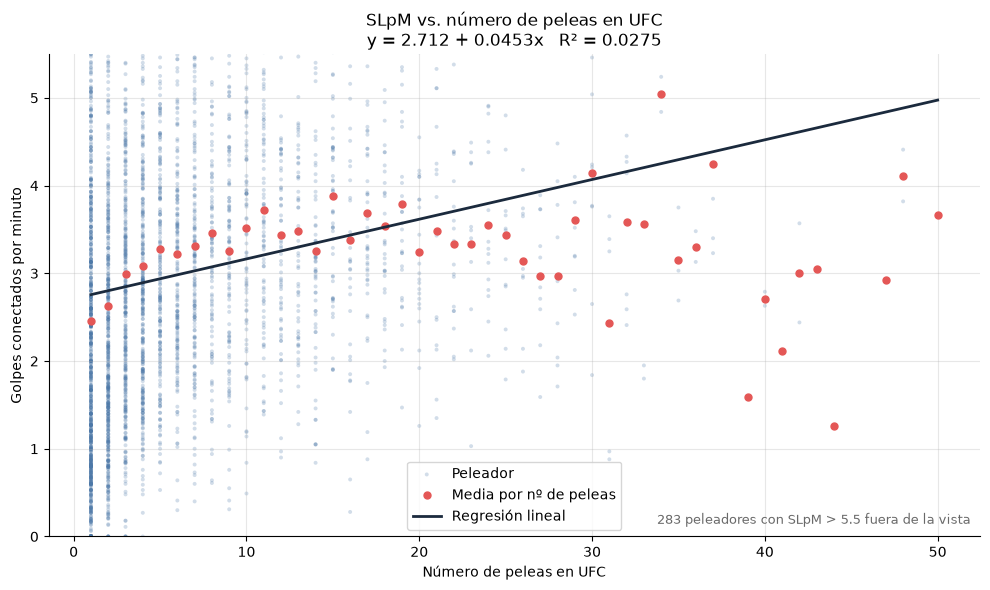

intercepto       2.7115
pendiente        0.0453
error_std        0.0045
t               10.1597
R2               0.0275
RMSE             1.7851
n             3659.0000
dtype: float64

In [6]:
# Regresión: SLpM ~ número de peleas en UFC
fight_df = pd.read_csv("fight.csv")

# Cada pelea cuenta para ambos peleadores (esquina roja y azul)
n_peleas = pd.concat([fight_df["r_id"], fight_df["b_id"]]).value_counts()

peleas_df = fighter_df.loc[
    stats_df.index, ["fighter_id", "fighter_name", "slpm"]
].copy()
peleas_df["n_peleas"] = peleas_df["fighter_id"].map(n_peleas).fillna(0).astype(int)

# Se excluyen peleadores con estadísticas pero sin peleas registradas en fight.csv
sin_peleas = (peleas_df["n_peleas"] == 0).sum()
peleas_df = peleas_df[peleas_df["n_peleas"] > 0]
print(
    f"Peleadores en la regresión: {len(peleas_df)} (excluidos {sin_peleas} sin peleas en fight.csv)"
)

X = peleas_df[["n_peleas"]].to_numpy(float)
y = peleas_df["slpm"].to_numpy(float)
modelo = LinearRegression().fit(X, y)
y_pred = modelo.predict(X)

n = len(y)
x = X[:, 0]
residuos = y - y_pred
se = np.sqrt(residuos @ residuos / (n - 2) / ((x - x.mean()) ** 2).sum())
pendiente, intercepto = modelo.coef_[0], modelo.intercept_
r2 = r2_score(y, y_pred)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, s=8, alpha=0.25, color="#4C78A8", edgecolors="none", label="Peleador")
# Media de SLpM por número de peleas, como referencia frente a la recta
medias = peleas_df.groupby("n_peleas")["slpm"].mean()
ax.plot(
    medias.index,
    medias.values,
    "o",
    color="#E45756",
    markersize=5,
    label="Media por nº de peleas",
)
xs = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
ax.plot(xs, modelo.predict(xs), color="#1B2A3D", linewidth=2, label="Regresión lineal")
ax.set_title(
    f"SLpM vs. número de peleas en UFC\ny = {intercepto:.3f} + {pendiente:.4f}x   R² = {r2:.4f}",
    fontsize=12,
)
ax.set_xlabel("Número de peleas en UFC")
ax.set_ylabel(estadisticas["slpm"])
# Solo se acota la vista: la regresión y las medias usan todos los datos
ax.set_ylim(0, 5.5)
fuera = (y > 5.5).sum()
ax.text(
    0.99,
    0.02,
    f"{fuera} peleadores con SLpM > 5.5 fuera de la vista",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    color="dimgray",
)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
fig.tight_layout()
plt.show()

pd.Series(
    {
        "intercepto": intercepto,
        "pendiente": pendiente,
        "error_std": se,
        "t": pendiente / se,
        "R2": r2,
        "RMSE": np.sqrt(mean_squared_error(y, y_pred)),
        "n": n,
    }
).round(4)

Peleadores con más de 4 peleas: 1543 de 3659
Lambdas de Yeo-Johnson: {'slpm': np.float64(0.475), 'td_avg': np.float64(-0.179), 'sub_avg': np.float64(-1.057)}


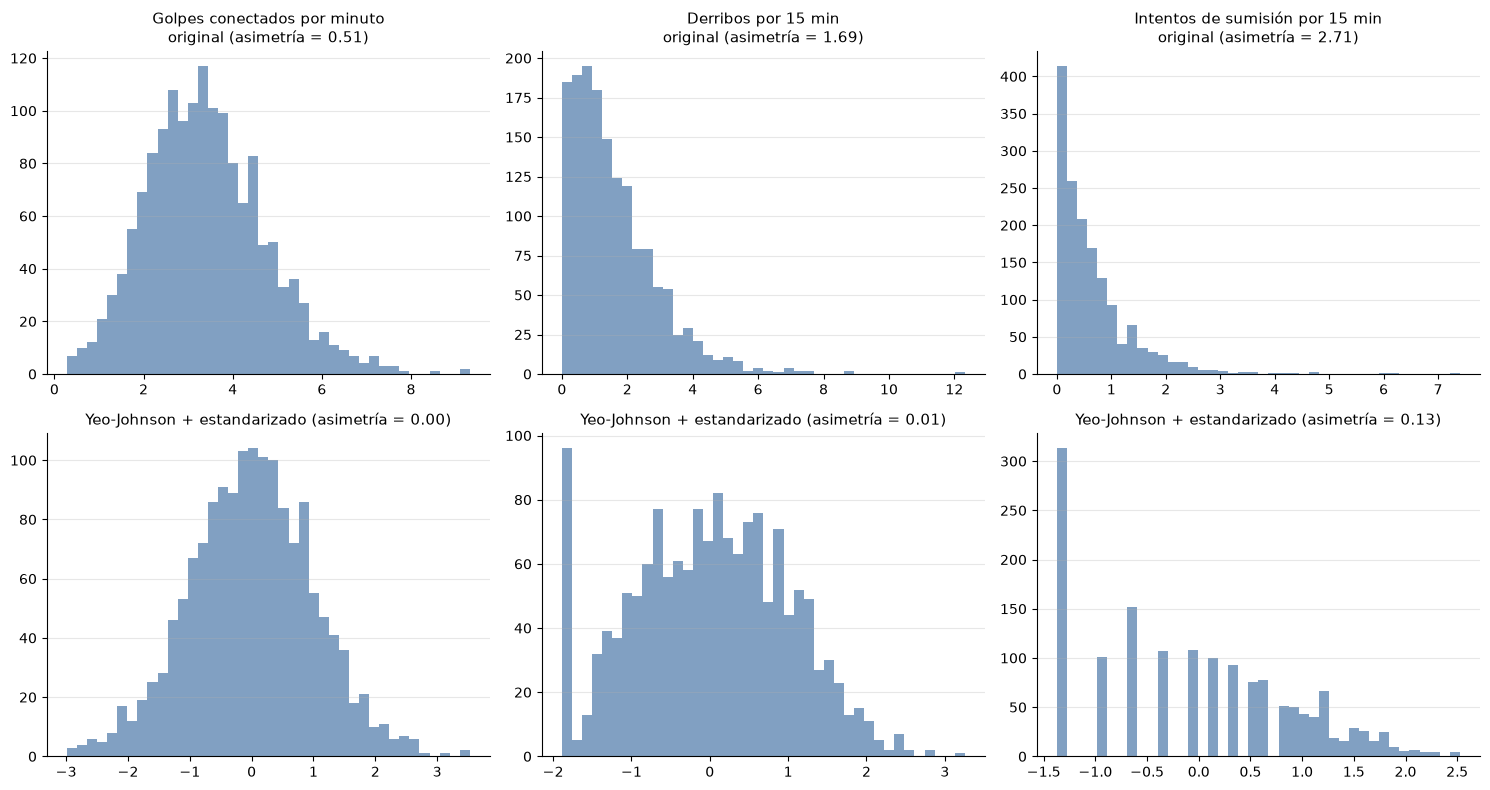

,slpm,td_avg,sub_avg
count,1543.000,1543.000,1543.000
mean,-0.000,0.000,0.000
std,1.000,1.000,1.000
min,-2.988,-1.888,-1.372
25%,-0.662,-0.727,-0.955
50%,0.004,0.024,-0.068
75%,0.684,0.725,0.774
max,3.529,3.256,2.526


In [7]:
from sklearn.preprocessing import PowerTransformer

# Se quitan los peleadores con 4 o menos peleas (sus estadísticas son muy inestables)
variables = ["slpm", "td_avg", "sub_avg"]
experimentados = peleas_df.loc[
    peleas_df["n_peleas"] > 4, ["fighter_id", "fighter_name", "n_peleas"]
]
ofensiva_df = experimentados.join(fighter_df[variables])
print(f"Peleadores con más de 4 peleas: {len(ofensiva_df)} de {len(peleas_df)}")

# Yeo-Johnson (admite ceros) + estandarización a media 0 y desviación 1
pt = PowerTransformer(method="yeo-johnson", standardize=True)
transformado_df = pd.DataFrame(
    pt.fit_transform(ofensiva_df[variables]),
    columns=variables,
    index=ofensiva_df.index,
)
print("Lambdas de Yeo-Johnson:", dict(zip(variables, pt.lambdas_.round(3))))

# Comparación de distribuciones antes y después
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, col in enumerate(variables):
    axes[0, j].hist(ofensiva_df[col], bins=40, color="#4C78A8", alpha=0.7)
    axes[0, j].set_title(
        f"{estadisticas[col]}\noriginal (asimetría = {ofensiva_df[col].skew():.2f})",
        fontsize=11,
    )
    axes[1, j].hist(transformado_df[col], bins=40, color="#4C78A8", alpha=0.7)
    axes[1, j].set_title(
        f"Yeo-Johnson + estandarizado (asimetría = {transformado_df[col].skew():.2f})",
        fontsize=11,
    )
for ax in axes.flat:
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

transformado_df.describe().round(3)

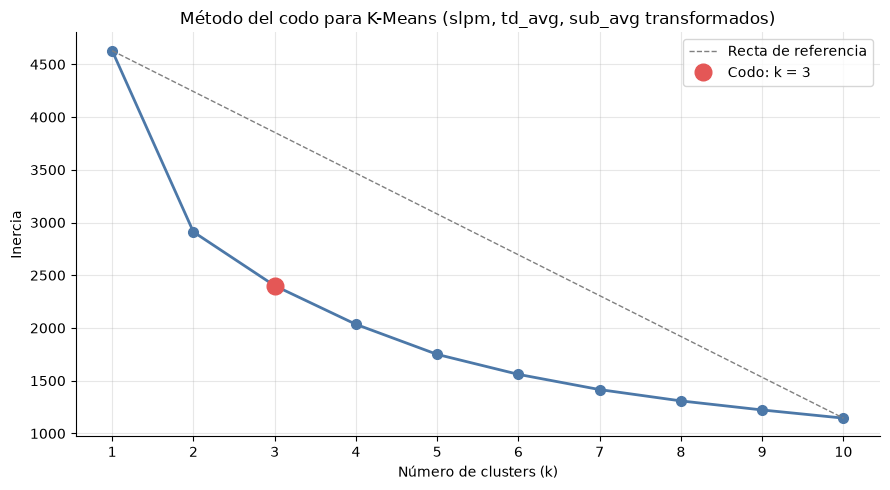

 k  inercia
 1   4629.0
 2   2910.7
 3   2400.7
 4   2034.6
 5   1749.5
 6   1560.2
 7   1415.9
 8   1308.7
 9   1222.8
10   1145.4

Número de clusters recomendado (codo): k = 3


In [ ]:
from sklearn.cluster import KMeans

# Método del codo: inercia (suma de distancias al cuadrado dentro de los clusters) para k = 1..10
valores_k = range(1, 11)
inercias = [
    KMeans(n_clusters=k, n_init=10, random_state=42).fit(transformado_df).inertia_
    for k in valores_k
]

# k recomendado (método Kneedle): con k e inercia normalizados a [0, 1], el codo es el
# punto más alejado de la recta que une el primer y el último punto de la curva
k_arr = np.array(valores_k, dtype=float)
i_arr = np.array(inercias)
k_norm = (k_arr - k_arr.min()) / (k_arr.max() - k_arr.min())
i_norm = (i_arr - i_arr.min()) / (i_arr.max() - i_arr.min())
distancia = np.abs(k_norm + i_norm - 1) / np.sqrt(
    2
)  # distancia a la recta (0, 1)-(1, 0)
k_optimo = int(k_arr[distancia.argmax()])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_arr, i_arr, "o-", color="#4C78A8", linewidth=2, markersize=7)
ax.plot(
    [k_arr[0], k_arr[-1]],
    [i_arr[0], i_arr[-1]],
    "--",
    color="gray",
    linewidth=1,
    label="Recta de referencia",
)
ax.plot(
    k_optimo,
    inercias[k_optimo - 1],
    "o",
    color="#E45756",
    markersize=12,
    label=f"Codo: k = {k_optimo}",
)
ax.set_xticks(k_arr)
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inercia")
ax.set_title(
    "Método del codo para K-Means (slpm, td_avg, sub_avg transformados)", fontsize=12
)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
fig.tight_layout()
plt.show()

print(
    pd.DataFrame({"k": valores_k, "inercia": np.round(inercias, 1)}).to_string(
        index=False
    )
)
print(f"\nNúmero de clusters recomendado (codo): k = {k_optimo}")

Peleadores por cluster:
cluster
0    792
1    751

Medias por cluster (valores originales):
         slpm  td_avg  sub_avg
cluster                       
0        4.13    0.93     0.23
1        2.64    2.28     1.08


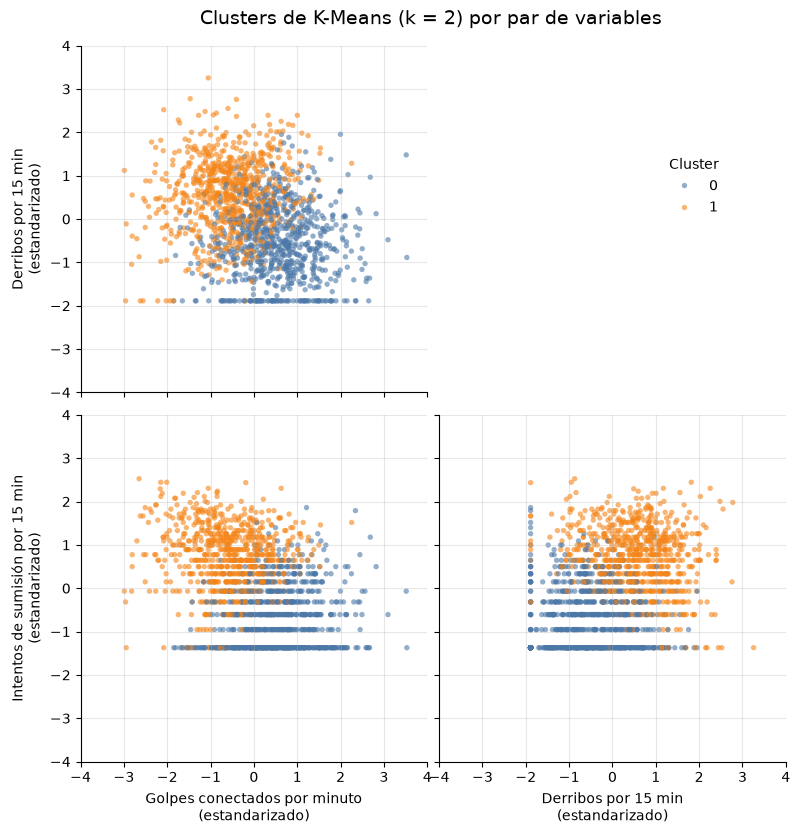

In [16]:
import seaborn as sns

# K-Means con k = 2, para probar, sobre las variables transformadas (Yeo-Johnson + estandarizadas)
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
ofensiva_df["cluster"] = kmeans.fit_predict(transformado_df[variables])

print("Peleadores por cluster:")
print(ofensiva_df["cluster"].value_counts().sort_index().to_string())
print("\nMedias por cluster (valores originales):")
print(ofensiva_df.groupby("cluster")[variables].mean().round(2).to_string())

# Pairplot en el espacio transformado (el que usa K-Means), con los 3 pares de variables:
# slpm-td_avg, slpm-sub_avg y td_avg-sub_avg
plot_df = transformado_df[variables].assign(cluster=ofensiva_df["cluster"])
g = sns.pairplot(
    plot_df,
    hue="cluster",
    palette=["#4C78A8", "#F58518"],
    x_vars=["slpm", "td_avg"],
    y_vars=["td_avg", "sub_avg"],
    plot_kws=dict(s=15, alpha=0.6, edgecolor="none"),
    height=4,
)
# El panel td_avg vs. td_avg (arriba a la derecha) es la variable contra sí misma: se oculta
for ax in [g.axes[0, 1], *(g.diag_axes if g.diag_axes is not None else [])]:
    ax.set_visible(False)
sns.move_legend(g, "upper right", bbox_to_anchor=(0.85, 0.85), title="Cluster")

# Misma escala en todos los ejes: mismos límites, mismas marcas y 1 unidad = misma longitud
limite = np.ceil(np.abs(plot_df[variables].to_numpy()).max() * 2) / 2
marcas = np.arange(-np.floor(limite), np.floor(limite) + 1)
paneles = {
    (0, 0): ("slpm", "td_avg"),
    (1, 0): ("slpm", "sub_avg"),
    (1, 1): ("td_avg", "sub_avg"),
}
for (i, j), (x_col, y_col) in paneles.items():
    ax = g.axes[i, j]
    ax.set_xlim(-limite, limite)
    ax.set_ylim(-limite, limite)
    ax.set_xticks(marcas)
    ax.set_yticks(marcas)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"{estadisticas[x_col]}\n(estandarizado)")
    ax.set_ylabel(f"{estadisticas[y_col]}\n(estandarizado)")
    ax.grid(alpha=0.3)
g.figure.suptitle(
    "Clusters de K-Means (k = 2) por par de variables", y=1.02, fontsize=14
)
plt.show()

Peleadores por cluster:
cluster
0    563
1    449
2    531

Medias por cluster (valores originales):
         slpm  td_avg  sub_avg
cluster                       
0        4.28    0.54     0.25
1        3.51    2.46     0.33
2        2.38    1.95     1.33


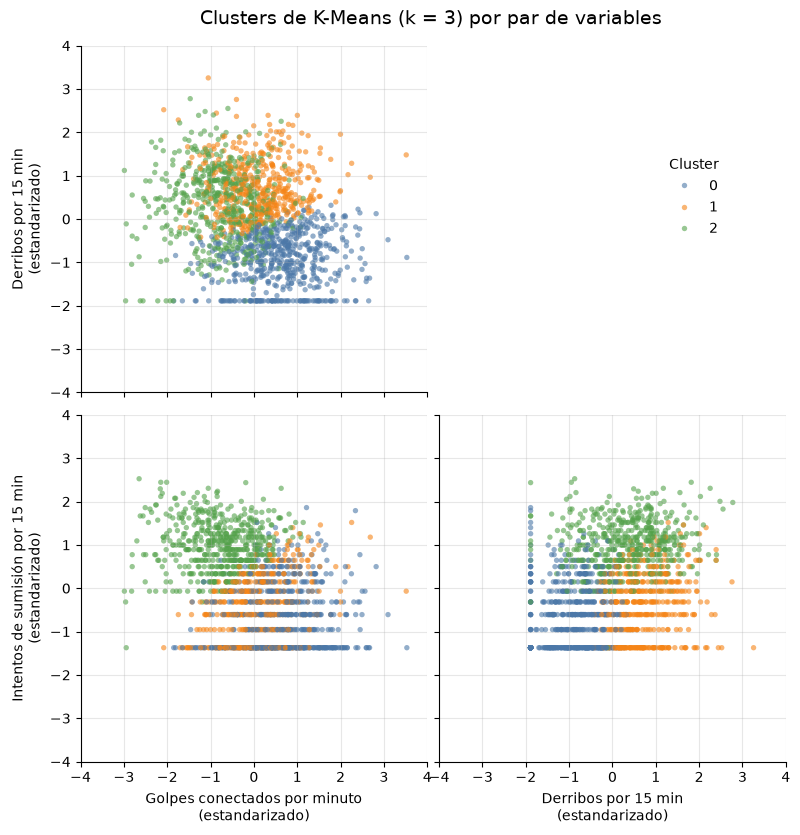

In [17]:
import seaborn as sns

# K-Means con k = 3 sobre las variables transformadas (Yeo-Johnson + estandarizadas)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
ofensiva_df["cluster"] = kmeans.fit_predict(transformado_df[variables])

print("Peleadores por cluster:")
print(ofensiva_df["cluster"].value_counts().sort_index().to_string())
print("\nMedias por cluster (valores originales):")
print(ofensiva_df.groupby("cluster")[variables].mean().round(2).to_string())

# Pairplot en el espacio transformado (el que usa K-Means), con los 3 pares de variables:
# slpm-td_avg, slpm-sub_avg y td_avg-sub_avg
plot_df = transformado_df[variables].assign(cluster=ofensiva_df["cluster"])
g = sns.pairplot(
    plot_df,
    hue="cluster",
    palette=["#4C78A8", "#F58518", "#54A24B"],
    x_vars=["slpm", "td_avg"],
    y_vars=["td_avg", "sub_avg"],
    plot_kws=dict(s=15, alpha=0.6, edgecolor="none"),
    height=4,
)
# El panel td_avg vs. td_avg (arriba a la derecha) es la variable contra sí misma: se oculta
for ax in [g.axes[0, 1], *(g.diag_axes if g.diag_axes is not None else [])]:
    ax.set_visible(False)
sns.move_legend(g, "upper right", bbox_to_anchor=(0.85, 0.85), title="Cluster")

# Misma escala en todos los ejes: mismos límites, mismas marcas y 1 unidad = misma longitud
limite = np.ceil(np.abs(plot_df[variables].to_numpy()).max() * 2) / 2
marcas = np.arange(-np.floor(limite), np.floor(limite) + 1)
paneles = {
    (0, 0): ("slpm", "td_avg"),
    (1, 0): ("slpm", "sub_avg"),
    (1, 1): ("td_avg", "sub_avg"),
}
for (i, j), (x_col, y_col) in paneles.items():
    ax = g.axes[i, j]
    ax.set_xlim(-limite, limite)
    ax.set_ylim(-limite, limite)
    ax.set_xticks(marcas)
    ax.set_yticks(marcas)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"{estadisticas[x_col]}\n(estandarizado)")
    ax.set_ylabel(f"{estadisticas[y_col]}\n(estandarizado)")
    ax.grid(alpha=0.3)
g.figure.suptitle(
    "Clusters de K-Means (k = 3) por par de variables", y=1.02, fontsize=14
)
plt.show()

In [ ]:
# Estilos de pelea a partir de los clusters de K-Means con k = 3 (celda anterior)
etiquetas_estilo = {0: "striker", 1: "luchador", 2: "sometedor"}
df_estilo = pd.DataFrame(
    {
        "fighter_id": ofensiva_df["fighter_id"].to_numpy(),
        "estilo": ofensiva_df["cluster"].map(etiquetas_estilo).to_numpy(),
    }
)

# Se añade el estilo al dataframe de peleadores, emparejando por ID
ofensiva_df["estilo"] = ofensiva_df["fighter_id"].map(
    df_estilo.set_index("fighter_id")["estilo"]
)
print(ofensiva_df["estilo"].value_counts().to_string())

peleadores = [
    "Max Holloway",
    "Charles Oliveira",
    "Alexander Volkanovski",
    "Khabib Nurmagomedov",
    "Islam Makhachev",
    "Conor McGregor",
    "Dustin Poirier",
    "Justin Gaethje",
    "Tony Ferguson",
    "Israel Adesanya",
]
# Hay nombres repetidos en los datos, por eso se filtra con isin en lugar de usar el nombre como índice
seleccion = ofensiva_df[ofensiva_df["fighter_name"].isin(peleadores)]
print()
print(seleccion[["fighter_name", "estilo"]].to_string(index=False))
faltantes = sorted(set(peleadores) - set(seleccion["fighter_name"]))
if faltantes:
    print("\nNo están en ofensiva_df (4 o menos peleas o sin estadísticas):", faltantes)

estilo
striker      563
sometedor    531
luchador     449

         fighter_name    estilo
      Islam Makhachev sometedor
       Conor McGregor   striker
        Tony Ferguson   striker
       Justin Gaethje   striker
         Max Holloway   striker
  Khabib Nurmagomedov  luchador
      Israel Adesanya   striker
     Charles Oliveira sometedor
       Dustin Poirier   striker
Alexander Volkanovski   striker


## Mejora 1: estilo de cada peleador al momento de cada pelea

Hasta ahora cada peleador tenía un solo estilo calculado con las estadísticas de toda su carrera.
Aquí se recalcula el estilo **antes de cada pelea**, usando solo sus peleas anteriores, con el mismo
`pt` (PowerTransformer) y el mismo `kmeans` (k = 3) ya entrenados.

Notas:
- "Anterior" significa de un **día anterior**: en los torneos antiguos algunos peleadores pelearon
  dos veces el mismo día y el orden dentro del día no es fiable.
- El historial se acumula con todas las peleas (incluidos empates y "no contest"), pero la tabla
  final solo conserva las peleas con `result_status == "win"`.

In [ ]:
import re

# Mejora 1 - Paso 1: duración de cada pelea en minutos
event_df = pd.read_csv("event.csv")
peleas_m1 = fight_df.merge(event_df[["event_id", "date"]], on="event_id")
peleas_m1["fecha"] = pd.to_datetime(peleas_m1["date"])


# En fight.csv, "round" y "time" son el round y el tiempo en que terminó la pelea.
# La duración de cada round sale de time_format, p. ej. "3 Rnd (5-5-5)" o "3 Rnd (10-5-5)".
def minutos_pelea(fila):
    duraciones = (
        re.findall(r"\d+", fila["time_format"].split("(")[-1])
        if "(" in fila["time_format"]
        else []
    )
    if duraciones:
        rounds_completos = sum(int(d) for d in duraciones[: fila["round"] - 1])
    else:
        rounds_completos = 5 * (fila["round"] - 1)  # sin formato: rounds de 5 min
    minutos, segundos = map(int, fila["time"].split(":"))
    return rounds_completos + minutos + segundos / 60


peleas_m1["minutos"] = peleas_m1.apply(minutos_pelea, axis=1)
print(peleas_m1[["time_format", "round", "time", "minutos"]].head())
print(
    f"\nPeleas: {len(peleas_m1)} | minutos promedio: {peleas_m1['minutos'].mean():.1f}"
)

            time_format  round   time    minutos
0         3 Rnd (5-5-5)      2   1:11   6.183333
1         3 Rnd (5-5-5)      3   2:04  12.066667
2         3 Rnd (5-5-5)      1   1:27   1.450000
3     1 Rnd + OT (12-3)      1  10:23  10.383333
4  1 Rnd + 2OT (15-3-3)      1   0:16   0.266667

Peleas: 11441 | minutos promedio: 10.2


In [29]:
# Mejora 1 - Paso 2: golpes significativos, derribos e intentos de sumisión de cada pelea (suma de rounds)
round_df = pd.read_csv("round.csv")
cols_round = [
    "r_sig_landed",
    "b_sig_landed",
    "r_td_success",
    "b_td_success",
    "r_sub_att",
    "b_sub_att",
]
stats_pelea = round_df.groupby("fight_id")[cols_round].sum().reset_index()

peleas_m1 = peleas_m1.merge(stats_pelea, on="fight_id", how="left")
peleas_m1["tiene_stats"] = peleas_m1["r_sig_landed"].notna()
print(f"Peleas sin estadísticas por round: {(~peleas_m1['tiene_stats']).sum()}")

Peleas sin estadísticas por round: 330


In [30]:
# Mejora 1 - Paso 3: tabla larga, una fila por peleador y pelea (cada pelea aparece dos veces)
columnas_esquina = {
    "r": {
        "r_id": "fighter_id",
        "b_id": "opp_id",
        "r_sig_landed": "golpes_sig",
        "r_td_success": "derribos",
        "r_sub_att": "int_sumision",
    },
    "b": {
        "b_id": "fighter_id",
        "r_id": "opp_id",
        "b_sig_landed": "golpes_sig",
        "b_td_success": "derribos",
        "b_sub_att": "int_sumision",
    },
}
comunes = ["fight_id", "fecha", "result_status", "winner_id", "minutos", "tiene_stats"]
historial = pd.concat(
    [
        peleas_m1[comunes + list(cols)].rename(columns=cols)
        for cols in columnas_esquina.values()
    ],
    ignore_index=True,
)
historial["gano"] = historial["winner_id"] == historial["fighter_id"]
# 1 = victoria, -1 = derrota, 0 = empate o "no contest"
historial["resultado"] = np.where(
    historial["result_status"] != "win", 0, np.where(historial["gano"], 1, -1)
)
print(f"Filas: {len(historial)} (2 x {len(peleas_m1)} peleas)")
historial.head()

Filas: 22882 (2 x 11441 peleas)


,fight_id,fecha,result_status,winner_id,minutos,tiene_stats,fighter_id,opp_id,golpes_sig,derribos,int_sumision,gano,resultado
0,4cd909fa0d3e0483,2006-11-11,win,c3ea8deeba00462b,6.183333,True,c3ea8deeba00462b,ad32471f01e7b1a5,12.0,0.0,0.0,True,1
1,5ac9cf4ffc15ccca,2003-09-26,win,f57a8a52ca401ed9,12.066667,True,f57a8a52ca401ed9,ad32471f01e7b1a5,17.0,6.0,2.0,True,1
2,e8ec95cdef577733,2002-06-22,win,79899ecf62020f6d,1.450000,True,79899ecf62020f6d,ad32471f01e7b1a5,11.0,1.0,0.0,True,1
3,db936df21e61209e,1998-03-13,win,93892752c5fc23ca,10.383333,True,93892752c5fc23ca,13b2f59210dda9cc,5.0,0.0,2.0,True,1
4,e0c636beed345e1d,1997-12-21,win,fcaae0385b514f11,0.266667,True,fcaae0385b514f11,13b2f59210dda9cc,1.0,0.0,1.0,True,1


In [31]:
# Mejora 1 - Paso 4: datos físicos del peleador (edad a la fecha de la pelea, alcance y altura en cm, guardia)
def altura_a_cm(texto):
    if pd.isna(texto):
        return np.nan
    pies, pulgadas = re.findall(r"\d+", texto)
    return (int(pies) * 12 + int(pulgadas)) * 2.54


fisicos = fighter_df[
    ["fighter_id", "fighter_name", "dob", "reach_inches", "height", "stance"]
].copy()
fisicos["altura_cm"] = fisicos["height"].apply(altura_a_cm)
fisicos["alcance_cm"] = fisicos["reach_inches"] * 2.54
fisicos["dob"] = pd.to_datetime(fisicos["dob"])
fisicos = fisicos.rename(columns={"stance": "guardia"})

historial = historial.merge(
    fisicos[
        ["fighter_id", "fighter_name", "dob", "altura_cm", "alcance_cm", "guardia"]
    ],
    on="fighter_id",
    how="left",
)
historial["edad"] = (historial["fecha"] - historial["dob"]).dt.days / 365.25
historial = historial.drop(columns="dob")
print(historial[["edad", "altura_cm", "alcance_cm"]].describe().round(1))
print(
    "\nFaltantes:",
    historial[["edad", "altura_cm", "alcance_cm", "guardia"]].isna().sum().to_dict(),
)

          edad  altura_cm  alcance_cm
count  22445.0    22632.0     19222.0
mean      30.1      178.5       182.8
std        4.2        9.0        10.9
min        4.6      139.7       147.3
25%       27.1      172.7       175.3
50%       29.9      177.8       182.9
75%       32.9      185.4       190.5
max       51.9      226.1       213.4

Faltantes: {'edad': 437, 'altura_cm': 250, 'alcance_cm': 3660, 'guardia': 636}


In [32]:
# Mejora 1 - Paso 5: estadísticas acumuladas con SOLO peleas de días anteriores
# Las peleas sin estadísticas por round no suman ni minutos ni golpes, para que las tasas sean coherentes
historial["min_stats"] = historial["minutos"].where(historial["tiene_stats"], 0)
for col in ["golpes_sig", "derribos", "int_sumision"]:
    historial[f"{col}_aux"] = historial[col].fillna(0)

por_dia = historial.groupby(["fighter_id", "fecha"])[
    ["min_stats", "golpes_sig_aux", "derribos_aux", "int_sumision_aux"]
].sum()
# Acumulado hasta ese día, menos lo de ese mismo día = solo días anteriores
previo = por_dia.groupby(level="fighter_id").cumsum() - por_dia
previo.columns = ["min_prev", "golpes_prev", "derribos_prev", "sumision_prev"]

historial = historial.merge(
    previo.reset_index(), on=["fighter_id", "fecha"], how="left"
)
minutos_validos = historial["min_prev"].where(historial["min_prev"] > 0)
historial["slpm_prev"] = historial["golpes_prev"] / minutos_validos
historial["td_avg_prev"] = historial["derribos_prev"] / minutos_validos * 15
historial["sub_avg_prev"] = historial["sumision_prev"] / minutos_validos * 15
print(
    historial[["min_prev", "slpm_prev", "td_avg_prev", "sub_avg_prev"]]
    .describe()
    .round(2)
)

       min_prev  slpm_prev  td_avg_prev  sub_avg_prev
count  22882.00   18511.00     18511.00      18511.00
mean      60.88       3.50         1.84          0.98
std       74.48       2.11         2.09          2.00
min        0.00       0.00         0.00          0.00
25%        6.23       2.29         0.47          0.00
50%       33.38       3.26         1.39          0.48
75%       87.45       4.33         2.61          1.23
max      532.72      56.00        52.94         58.06


In [33]:
# Mejora 1 - Paso 6: peleas UFC previas, racha y días desde la pelea anterior (solo días anteriores)
# Dentro de un mismo día se ordenan primero las victorias: en un torneo, quien pelea dos veces ganó la primera
historial = historial.sort_values(
    ["fighter_id", "fecha", "resultado"], ascending=[True, True, False]
)


def rachas_despues(resultados):
    """Racha después de cada pelea: +n victorias seguidas, -n derrotas seguidas, 0 tras empate o NC."""
    rachas, actual = [], 0
    for r in resultados:
        if r == 1:
            actual = actual + 1 if actual > 0 else 1
        elif r == -1:
            actual = actual - 1 if actual < 0 else -1
        else:
            actual = 0
        rachas.append(actual)
    return rachas


historial["racha_despues"] = historial.groupby("fighter_id")["resultado"].transform(
    lambda s: pd.Series(rachas_despues(s.tolist()), index=s.index)
)

resumen_dia = (
    historial.groupby(["fighter_id", "fecha"])
    .agg(peleas_dia=("fight_id", "size"), racha_fin_dia=("racha_despues", "last"))
    .reset_index()
)
grupo = resumen_dia.groupby("fighter_id")
resumen_dia["peleas_previas"] = grupo["peleas_dia"].cumsum() - resumen_dia["peleas_dia"]
resumen_dia["racha"] = grupo["racha_fin_dia"].shift(1).fillna(0).astype(int)
resumen_dia["dias_desde_anterior"] = grupo["fecha"].diff().dt.days

historial = historial.merge(
    resumen_dia[
        ["fighter_id", "fecha", "peleas_previas", "racha", "dias_desde_anterior"]
    ],
    on=["fighter_id", "fecha"],
    how="left",
)
print(historial[["peleas_previas", "racha", "dias_desde_anterior"]].describe().round(1))

       peleas_previas    racha  dias_desde_anterior
count         22882.0  22882.0              18703.0
mean              6.0      0.5                227.7
std               6.8      2.0                232.8
min               0.0     -7.0                  1.0
25%               1.0     -1.0                119.0
50%               4.0      0.0                168.0
75%               9.0      1.0                252.0
max              49.0     17.0               3906.0


In [34]:
# Mejora 1 - Paso 7: estilo al momento de la pelea con el MISMO pt y el MISMO kmeans (sin reentrenar)
assert kmeans.n_clusters == 3, (
    "kmeans debe ser el modelo de k = 3 (la celda de k = 3 corre después de la de k = 2)"
)
min_historial = 15  # minutos mínimos de historial con estadísticas

con_historial = historial["min_prev"] >= min_historial
X_prev = historial.loc[con_historial, ["slpm_prev", "td_avg_prev", "sub_avg_prev"]]
X_prev.columns = (
    variables  # mismos nombres de columnas que al entrenar: slpm, td_avg, sub_avg
)

X_prev_t = pd.DataFrame(pt.transform(X_prev), columns=variables, index=X_prev.index)
historial["cluster_prev"] = pd.Series(kmeans.predict(X_prev_t), index=X_prev.index)
historial["estilo"] = historial["cluster_prev"].map(
    etiquetas_estilo
)  # 0 striker, 1 luchador, 2 sometedor

print(
    f"Filas con al menos {min_historial} min de historial: {con_historial.sum()} de {len(historial)}"
)
print(historial["estilo"].value_counts(dropna=False).to_string())

Filas con al menos 15 min de historial: 15769 de 22882
estilo
NaN          7113
sometedor    6261
striker      5227
luchador     4281


In [35]:
# Mejora 1 - Paso 8: solo peleas con ganador y variables del rival con prefijo opp_
vars_peleador = [
    "edad",
    "altura_cm",
    "alcance_cm",
    "guardia",
    "golpes_sig",
    "derribos",
    "int_sumision",
    "min_prev",
    "slpm_prev",
    "td_avg_prev",
    "sub_avg_prev",
    "estilo",
    "peleas_previas",
    "racha",
    "dias_desde_anterior",
]
peleas_estilo_df = historial.loc[
    historial["result_status"] == "win",
    ["fight_id", "fecha", "fighter_id", "fighter_name", "opp_id", "gano", "minutos"]
    + vars_peleador,
]
rival = historial[["fight_id", "fighter_id", "fighter_name"] + vars_peleador].rename(
    columns={
        "fighter_id": "opp_id",
        **{c: f"opp_{c}" for c in ["fighter_name"] + vars_peleador},
    }
)
peleas_estilo_df = peleas_estilo_df.merge(rival, on=["fight_id", "opp_id"], how="left")
peleas_estilo_df = peleas_estilo_df.sort_values(["fecha", "fight_id"]).reset_index(
    drop=True
)

# Ojo: golpes_sig, derribos e int_sumision (y sus opp_) son de ESTA pelea: sirven para describirla,
# pero no se pueden usar para predecir el resultado en la Mejora 3
print(
    f"Filas: {len(peleas_estilo_df)} ({peleas_estilo_df['fight_id'].nunique()} peleas x 2)"
)
print(f"Columnas: {peleas_estilo_df.shape[1]}")
peleas_estilo_df.head()

Filas: 22476 (11238 peleas x 2)
Columnas: 38


,fight_id,fecha,fighter_id,fighter_name,opp_id,gano,minutos,edad,altura_cm,alcance_cm,...,opp_derribos,opp_int_sumision,opp_min_prev,opp_slpm_prev,opp_td_avg_prev,opp_sub_avg_prev,opp_estilo,opp_peleas_previas,opp_racha,opp_dias_desde_anterior
0,00b0796724ec1c09,1993-11-12,02fc8f50f56eb307,Trent Jenkins,6ceff86fae4f6b3b,False,0.866667,NaN,187.96,NaN,...,1.0,1.0,0.0,NaN,NaN,NaN,NaN,0,0,NaN
1,00b0796724ec1c09,1993-11-12,6ceff86fae4f6b3b,Jason DeLucia,02fc8f50f56eb307,True,0.866667,24.303901,180.34,NaN,...,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0,0,NaN
2,2d2bbc86e941e05c,1993-11-12,598a58db87b890ee,Kevin Rosier,d3711d3784b76255,True,4.333333,NaN,193.04,NaN,...,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0,0,NaN
3,2d2bbc86e941e05c,1993-11-12,d3711d3784b76255,Zane Frazier,598a58db87b890ee,False,4.333333,NaN,195.58,NaN,...,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0,0,NaN
4,46acd54cc0c905fb,1993-11-12,46c8ec317aff28ac,Patrick Smith,63b65af1c5cb02cb,False,1.816667,30.209446,187.96,NaN,...,1.0,2.0,0.0,NaN,NaN,NaN,NaN,0,0,NaN


### Verificación de la tabla de la Mejora 1

In [36]:
# Verificación 1: no se usa información de la pelea actual ni de peleas futuras
# a) Revisión automática: para 300 filas al azar se recalcula el acumulado filtrando solo días anteriores
muestra = historial.sample(300, random_state=42)
errores = 0
for _, fila in muestra.iterrows():
    anteriores = historial[
        (historial["fighter_id"] == fila["fighter_id"])
        & (historial["fecha"] < fila["fecha"])
    ]
    ok = (
        np.isclose(anteriores["golpes_sig_aux"].sum(), fila["golpes_prev"])
        and np.isclose(anteriores["min_stats"].sum(), fila["min_prev"])
        and len(anteriores) == fila["peleas_previas"]
    )
    errores += not ok
print(f"Filas revisadas: {len(muestra)} | con error: {errores}")

# b) La primera pelea de cada peleador no puede tener historial
primeras = historial[historial["peleas_previas"] == 0]
print(
    f"Primeras peleas: {len(primeras)} | con minutos previos: {(primeras['min_prev'] > 0).sum()} "
    f"| con estilo: {primeras['estilo'].notna().sum()}"
)

Filas revisadas: 300 | con error: 0
Primeras peleas: 4179 | con minutos previos: 0 | con estilo: 0


In [37]:
# c) Un peleador conocido, pelea por pelea: golpes_prev debe ser la suma de golpes_sig de las filas anteriores
cols_ver = [
    "fecha",
    "opp_fighter_name",
    "gano",
    "minutos",
    "golpes_sig",
    "min_prev",
    "slpm_prev",
    "td_avg_prev",
    "sub_avg_prev",
    "estilo",
    "peleas_previas",
    "racha",
    "dias_desde_anterior",
]
holloway = peleas_estilo_df[peleas_estilo_df["fighter_name"] == "Max Holloway"]
holloway[cols_ver].round(2)

C:\Users\alexs\AppData\Local\Temp\ipykernel_19760\2902946974.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  holloway[cols_ver].round(2)


,fecha,opp_fighter_name,gano,minutos,golpes_sig,min_prev,slpm_prev,td_avg_prev,sub_avg_prev,estilo,peleas_previas,racha,dias_desde_anterior
7537,2012-02-04,Dustin Poirier,False,3.38,11.0,0.00,NaN,NaN,NaN,NaN,0,0,NaN
7796,2012-06-01,Pat Schilling,True,15.00,118.0,3.38,3.25,0.00,0.00,NaN,1,-1,118.0
7972,2012-08-11,Justin Lawrence,True,9.82,29.0,18.38,7.02,0.00,0.00,striker,2,1,71.0
8214,2012-12-29,Leonard Garcia,True,15.00,120.0,28.20,5.60,0.00,0.00,striker,3,2,140.0
8538,2013-05-25,Dennis Bermudez,False,15.00,75.0,43.20,6.44,0.00,0.00,striker,4,3,147.0
8690,2013-08-17,Conor McGregor,False,15.00,23.0,58.20,6.07,0.00,0.00,striker,5,-1,84.0
9024,2014-01-04,Will Chope,True,7.45,74.0,73.20,5.14,0.00,0.00,striker,6,-2,140.0
9300,2014-04-26,Andre Fili,True,13.65,47.0,80.65,5.58,0.00,0.00,striker,7,1,112.0
9632,2014-08-23,Clay Collard,True,13.78,124.0,94.30,5.27,0.00,0.32,striker,8,2,119.0
9800,2014-10-04,Akira Corassani,True,3.18,31.0,108.08,5.75,0.00,0.28,striker,9,3,42.0


In [38]:
# Verificación 2: los estilos tienen sentido
# a) Distribución de estilos por fila y medias de las estadísticas previas por estilo
print(peleas_estilo_df["estilo"].value_counts(dropna=False).to_string())
print()
print(
    peleas_estilo_df.groupby("estilo")[["slpm_prev", "td_avg_prev", "sub_avg_prev"]]
    .mean()
    .round(2)
    .to_string()
)

# b) Coincidencia con el estilo de carrera en la última pelea de cada peleador
ultima = (
    peleas_estilo_df.dropna(subset=["estilo"])
    .sort_values("fecha")
    .groupby("fighter_id")
    .last()
)
ultima["estilo_carrera"] = ultima.index.map(df_estilo.set_index("fighter_id")["estilo"])
comparables = ultima.dropna(subset=["estilo_carrera"])
print(
    f"\nCoincide con el estilo de carrera en su última pelea: "
    f"{(comparables['estilo'] == comparables['estilo_carrera']).mean():.1%} de {len(comparables)} peleadores"
)

estilo
NaN          6997
sometedor    6154
striker      5123
luchador     4202

           slpm_prev  td_avg_prev  sub_avg_prev
estilo                                         
luchador        3.59         2.81          0.32
sometedor       2.48         2.13          1.57
striker         4.35         0.47          0.24

Coincide con el estilo de carrera en su última pelea: 93.4% de 1525 peleadores


In [39]:
# c) Evolución del estilo de peleadores conocidos (inicial de cada estilo en orden cronológico)
inicial = {"striker": "S", "luchador": "L", "sometedor": "M"}  # M = soMetedor
for nombre in peleadores:
    filas = peleas_estilo_df[peleas_estilo_df["fighter_name"] == nombre]
    secuencia = "".join(inicial.get(e, "-") for e in filas["estilo"])
    print(f"{nombre:<22} {secuencia}")
print(
    "\n- = sin estilo todavía (menos de 15 min de historial) | S striker | L luchador | M sometedor"
)

Max Holloway           --SSSSSSSSSSSSSSSSSSSSSSSSSSSSSSS
Charles Oliveira       ---MMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMM
Alexander Volkanovski  --LLLLLLLLLLSSLLLS
Khabib Nurmagomedov    --MLMLLLLLLLL
Islam Makhachev        ---MMMMMMMMMMMMMMM
Conor McGregor         --LLLLLLSSSSSSS
Dustin Poirier         -MMSMMMMMMMMMMMMMMMLLLLLLLLLLLLLL
Justin Gaethje         --SSSSSSSSSSSSSS
Tony Ferguson          ---LSLLMMMMMMSSSSSSSSSSS
Israel Adesanya        --SSSSSSSSSSSSSSSSS

- = sin estilo todavía (menos de 15 min de historial) | S striker | L luchador | M sometedor


In [40]:
# Verificación 3: cuántas peleas se pierden por falta de historial
por_pelea = peleas_estilo_df.groupby("fight_id").agg(
    estilos_presentes=("estilo", lambda s: s.notna().sum())
)
print("Peleas con ganador:", len(por_pelea))
print("  ambos peleadores con estilo:", (por_pelea["estilos_presentes"] == 2).sum())
print("  solo uno con estilo:        ", (por_pelea["estilos_presentes"] == 1).sum())
print("  ninguno con estilo:         ", (por_pelea["estilos_presentes"] == 0).sum())

# Motivo de que una fila no tenga estilo
sin_estilo = peleas_estilo_df[peleas_estilo_df["estilo"].isna()]
motivo = np.where(
    sin_estilo["peleas_previas"] == 0,
    "debut en UFC",
    "menos de 15 min con estadísticas",
)
print()
print(pd.Series(motivo).value_counts().to_string())

Peleas con ganador: 11238
  ambos peleadores con estilo: 6219
  solo uno con estilo:         3041
  ninguno con estilo:          1978

debut en UFC                        4109
menos de 15 min con estadísticas    2888


## Mejora 2: ¿qué estilo gana cuando se enfrentan estilos distintos?

Se comparan dos peleadores **en la misma pelea**, así el rival queda controlado por diseño.
Con 3 estilos solo hay 3 enfrentamientos distintos (una matriz 3x3 repetiría información:
la diagonal siempre es 50% y cada celda es el espejo de su opuesta).

- Solo peleas donde ambos peleadores tienen estilo (al menos 15 min de historial) y los estilos son distintos.
- Cada pelea se cuenta una sola vez, siempre desde el punto de vista del estilo que va primero en
  orden alfabético (luchador < sometedor < striker). La esquina roja/azul no se usa.

In [41]:
# Mejora 2 - Paso 1: una fila por pelea entre estilos distintos
entre_estilos = peleas_estilo_df[
    peleas_estilo_df["estilo"].notna()
    & peleas_estilo_df["opp_estilo"].notna()
    & (peleas_estilo_df["estilo"] != peleas_estilo_df["opp_estilo"])
]
print(
    f"Filas con estilos distintos: {len(entre_estilos)} (cada pelea aparece dos veces)"
)

# De las dos filas de cada pelea se queda la del estilo que va primero en orden alfabético
enfrentamientos = entre_estilos[
    entre_estilos["estilo"] < entre_estilos["opp_estilo"]
].copy()
enfrentamientos["enfrentamiento"] = (
    enfrentamientos["estilo"] + " vs " + enfrentamientos["opp_estilo"]
)
print(
    f"Peleas únicas: {len(enfrentamientos)} | fight_id repetidos: {enfrentamientos['fight_id'].duplicated().sum()}"
)
print(enfrentamientos["enfrentamiento"].value_counts().to_string())

Filas con estilos distintos: 7142 (cada pelea aparece dos veces)
Peleas únicas: 3571 | fight_id repetidos: 0
enfrentamiento
luchador vs sometedor    1211
luchador vs striker      1182
sometedor vs striker     1178


In [42]:
# Mejora 2 - Paso 2: % de victorias del primer estilo e intervalo de confianza del 95%
def tabla_enfrentamientos(datos):
    tabla = datos.groupby("enfrentamiento")["gano"].agg(peleas="size", p="mean")
    error = 1.96 * np.sqrt(tabla["p"] * (1 - tabla["p"]) / tabla["peleas"])
    tabla["pct_victorias_primero"] = tabla["p"] * 100
    tabla["ic_inferior"] = (tabla["p"] - error) * 100
    tabla["ic_superior"] = (tabla["p"] + error) * 100
    return tabla.drop(columns="p")


resultado_estilos = tabla_enfrentamientos(enfrentamientos)
resultado_estilos.round(1)

,peleas,pct_victorias_primero,ic_inferior,ic_superior
enfrentamiento,,,,
luchador vs sometedor,1211,51.2,48.4,54.0
luchador vs striker,1182,56.1,53.3,58.9
sometedor vs striker,1178,52.1,49.3,55.0


In [43]:
# Mejora 2 - Paso 3: datos para la gráfica, desde el punto de vista del estilo que gana más
grafica_estilos = resultado_estilos.reset_index()
grafica_estilos[["primero", "segundo"]] = grafica_estilos["enfrentamiento"].str.split(
    " vs ", expand=True
)

gana_primero = grafica_estilos["pct_victorias_primero"] >= 50
grafica_estilos["ganador"] = np.where(
    gana_primero, grafica_estilos["primero"], grafica_estilos["segundo"]
)
grafica_estilos["perdedor"] = np.where(
    gana_primero, grafica_estilos["segundo"], grafica_estilos["primero"]
)
# Si gana el segundo estilo, su % y su intervalo son el espejo: 100 - valor
grafica_estilos["pct_ganador"] = np.where(
    gana_primero,
    grafica_estilos["pct_victorias_primero"],
    100 - grafica_estilos["pct_victorias_primero"],
)
grafica_estilos["ic_inf_ganador"] = np.where(
    gana_primero, grafica_estilos["ic_inferior"], 100 - grafica_estilos["ic_superior"]
)
grafica_estilos["ic_sup_ganador"] = np.where(
    gana_primero, grafica_estilos["ic_superior"], 100 - grafica_estilos["ic_inferior"]
)
grafica_estilos["ventaja_clara"] = grafica_estilos["ic_inf_ganador"] > 50
grafica_estilos = grafica_estilos.sort_values("pct_ganador")
grafica_estilos[
    [
        "ganador",
        "perdedor",
        "peleas",
        "pct_ganador",
        "ic_inf_ganador",
        "ic_sup_ganador",
        "ventaja_clara",
    ]
].round(1)

,ganador,perdedor,peleas,pct_ganador,ic_inf_ganador,ic_sup_ganador,ventaja_clara
0,luchador,sometedor,1211,51.2,48.4,54.0,False
2,sometedor,striker,1178,52.1,49.3,55.0,False
1,luchador,striker,1182,56.1,53.3,58.9,True


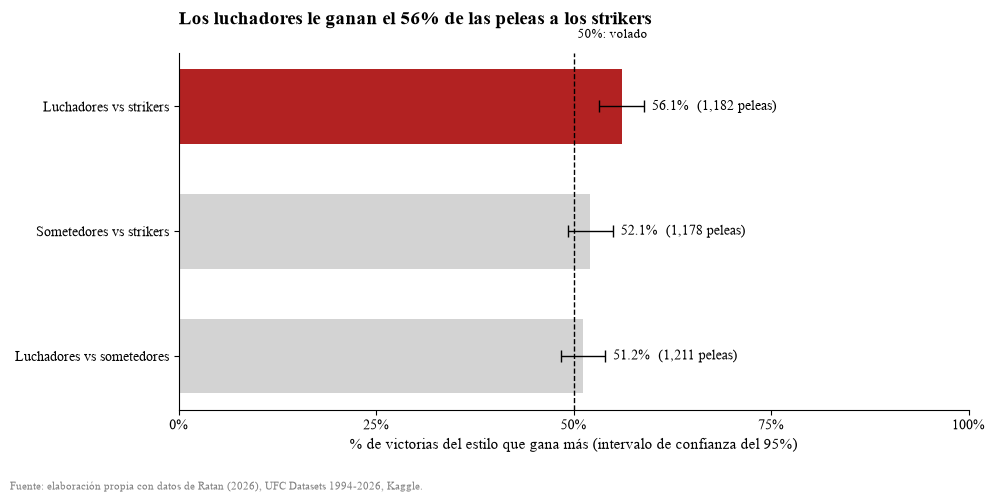

In [44]:
# Mejora 2 - Paso 4: gráfica de barras horizontales
LABEL_FONT = 11
plt.rcParams["font.family"] = "Times New Roman"

plural = {"striker": "strikers", "luchador": "luchadores", "sometedor": "sometedores"}
etiquetas = [
    f"{plural[g].capitalize()} vs {plural[p]}"
    for g, p in zip(grafica_estilos["ganador"], grafica_estilos["perdedor"])
]
colores = [
    "firebrick" if clara else "lightgray" for clara in grafica_estilos["ventaja_clara"]
]
error_inf = grafica_estilos["pct_ganador"] - grafica_estilos["ic_inf_ganador"]
error_sup = grafica_estilos["ic_sup_ganador"] - grafica_estilos["pct_ganador"]

# El título resume el hallazgo principal: el enfrentamiento con la ventaja más grande
mayor = grafica_estilos.iloc[-1]
titulo = (
    f"Los {plural[mayor['ganador']]} le ganan el {mayor['pct_ganador']:.0f}% de las peleas "
    f"a los {plural[mayor['perdedor']]}"
)

plt.figure(figsize=(10, 5))
plt.barh(etiquetas, grafica_estilos["pct_ganador"], color=colores, height=0.6)
plt.errorbar(
    grafica_estilos["pct_ganador"],
    etiquetas,
    xerr=[error_inf, error_sup],
    fmt="none",
    ecolor="black",
    capsize=4,
    linewidth=1,
)
plt.axvline(50, color="black", linestyle="--", linewidth=1)
plt.text(50.5, len(etiquetas) - 0.45, "50%: volado", fontsize=9)
for y, (pct, n, sup) in enumerate(
    zip(
        grafica_estilos["pct_ganador"],
        grafica_estilos["peleas"],
        grafica_estilos["ic_sup_ganador"],
    )
):
    plt.text(sup + 1, y, f"{pct:.1f}%  ({n:,} peleas)", va="center", fontsize=10)

plt.title(titulo + "\n", fontsize=14, fontweight="bold", loc="left")
plt.xlabel(
    "% de victorias del estilo que gana más (intervalo de confianza del 95%)",
    fontsize=LABEL_FONT,
)
plt.xlim(0, 100)
plt.xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(
    0.01,
    0.01,
    "Fuente: elaboración propia con datos de Ratan (2026), UFC Datasets 1994-2026, Kaggle.",
    fontsize=8,
    color="gray",
)
plt.tight_layout()
plt.subplots_adjust(bottom=0.17)
plt.savefig("ventaja_por_estilo.png", dpi=300)
plt.show()

In [45]:
# Mejora 2 - Paso 5: la misma tabla separada por época
enfrentamientos["epoca"] = np.where(
    enfrentamientos["fecha"] < "2015-01-01", "antes de 2015", "desde 2015"
)
for epoca, datos in enfrentamientos.groupby("epoca"):
    print(f"\n{epoca} ({len(datos)} peleas)")
    print(tabla_enfrentamientos(datos).round(1).to_string())


antes de 2015 (1125 peleas)
                       peleas  pct_victorias_primero  ic_inferior  ic_superior
enfrentamiento                                                                
luchador vs sometedor     515                   52.8         48.5         57.1
luchador vs striker       176                   58.0         50.7         65.2
sometedor vs striker      434                   52.5         47.8         57.2

desde 2015 (2446 peleas)
                       peleas  pct_victorias_primero  ic_inferior  ic_superior
enfrentamiento                                                                
luchador vs sometedor     696                   50.0         46.3         53.7
luchador vs striker      1006                   55.8         52.7         58.8
sometedor vs striker      744                   51.9         48.3         55.5
